In [2]:
import os 
from tqdm import tqdm 
import tensorflow as tf
import keras
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
import numpy as np

In [3]:
DATA_PATH_TRAINING = ('../data/Training/')

x = []
y = []
counter = 0

classes = os.listdir(DATA_PATH_TRAINING)
print(classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


## Preprocessing

In [4]:
for class_name in os.listdir(DATA_PATH_TRAINING):
    for fileName in tqdm(os.listdir(f"{DATA_PATH_TRAINING}{class_name}")):
        path = f"{DATA_PATH_TRAINING}{class_name}/{fileName}"
        label = counter

        image = tf.keras.preprocessing.image.load_img(path, target_size=(224, 224), color_mode="grayscale")
        image = tf.keras.preprocessing.image.img_to_array(image)

        x.append(image)
        y.append(label)

    counter += 1

100%|██████████| 1400/1400 [00:02<00:00, 584.30it/s]


In [5]:
x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

print(x.shape)
print(y.shape)

(5600, 224, 224, 1)
(5600,)


In [6]:
DATA_PATH_TESTING = ('../data/Testing/')
X_testing = []
y_testing = []
counter = 0

classes_test = os.listdir(DATA_PATH_TESTING)

In [7]:
for classes_test_name in os.listdir(DATA_PATH_TESTING): 
    for fileName_test in tqdm(os.listdir(f"{DATA_PATH_TESTING}{classes_test_name}")):
        path_test = f"{DATA_PATH_TESTING}{classes_test_name}/{fileName_test}"
        label_test = counter

        image_test = tf.keras.preprocessing.image.load_img(path_test, target_size=(224, 224), color_mode='grayscale')
        image_test = tf.keras.preprocessing.image.img_to_array(image_test)

        X_testing.append(image_test)
        y_testing.append(label_test)
        
    counter += 1

100%|██████████| 400/400 [00:00<00:00, 801.12it/s]


In [8]:
X_testing = np.array(X_testing)
y_testing = np.array(y_testing)

X_testing = X_testing.astype('float32') / 255.0

y_testing = keras.utils.to_categorical(y_testing)

## Train Test Split

In [9]:
# 80 : 20 (train : val)

X_train, X_val, y_train, y_val = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

# Ubah label jadi One Hot Encoder
y_train = keras.utils.to_categorical(y_train)
y_val = keras.utils.to_categorical(y_val)

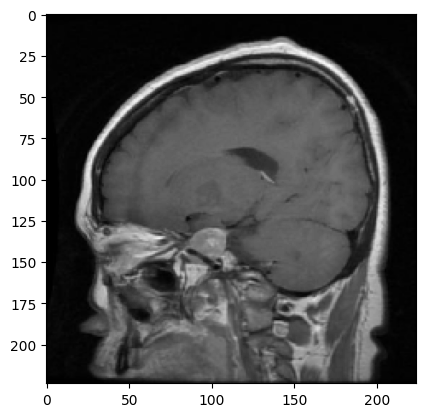

In [10]:
plt.imshow(X_train[0], cmap='gray')

## Model Architecture

In [11]:
data_augmentation = keras.Sequential([
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomZoom(0.1), 
    keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

In [12]:
model = keras.Sequential([
    keras.layers.Input(shape=(224,224,1)),
    data_augmentation,
    keras.layers.Conv2D(16, (5,5), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Conv2D(32, (5,5), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Conv2D(64, (5,5), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Flatten(),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.4),
    keras.layers.Dense(4, activation='softmax'),
])

print(model.summary())

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (None, 224, 224, 1)       0         
                                                                 
 conv2d (Conv2D)             (None, 220, 220, 16)      416       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 110, 110, 16)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 106, 106, 32)      12832     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 53, 53, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 49, 49, 64)       

In [13]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['Accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience = 5,
    restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath='../models/brain_tumor_model_earlystopping_4.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

history = model.fit(
    X_train, y_train, batch_size=120, validation_data=(X_val, y_val), epochs=30, callbacks=[early_stopping, checkpoint]
)

Epoch 1/30
38/38 [==============================] - 88s 2s/step - loss: 1.2231 - Accuracy: 0.4283 - val_loss: 0.8801 - val_Accuracy: 0.6027
Epoch 2/30
38/38 [==============================] - 141s 4s/step - loss: 0.9022 - Accuracy: 0.6196 - val_loss: 1.1471 - val_Accuracy: 0.5437
Epoch 3/30
38/38 [==============================] - 169s 4s/step - loss: 0.7655 - Accuracy: 0.6835 - val_loss: 0.7057 - val_Accuracy: 0.7161
Epoch 4/30
38/38 [==============================] - 217s 6s/step - loss: 0.7302 - Accuracy: 0.7049 - val_loss: 0.7513 - val_Accuracy: 0.7063
Epoch 5/30
38/38 [==============================] - 202s 5s/step - loss: 0.6841 - Accuracy: 0.7185 - val_loss: 0.8821 - val_Accuracy: 0.6946
Epoch 6/30
38/38 [==============================] - 193s 5s/step - loss: 0.6588 - Accuracy: 0.7357 - val_loss: 0.6479 - val_Accuracy: 0.7527
Epoch 7/30
38/38 [==============================] - 184s 5s/step - loss: 0.6610 - Accuracy: 0.7368 - val_loss: 0.5062 - val_Accuracy: 0.7964
Epoch 8/30
38/

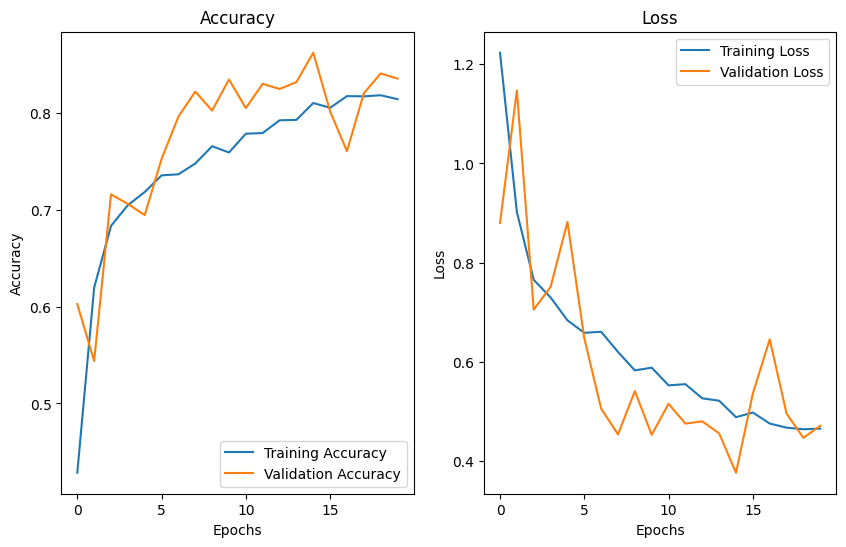

In [14]:
plt.figure(figsize=(10, 6))

# Accuracy Plotting
plt.subplot(1, 2, 1)
plt.plot(history.history['Accuracy'], label='Training Accuracy')
plt.plot(history.history['val_Accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

# Loss Plotting
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.show()

In [15]:
score = model.evaluate(X_testing, y_testing)
print(f"Test Loss = {score[0]}")
print(f"Test Accuracy = {score[1]}")

50/50 [==============================] - 22s 440ms/step - loss: 0.9301 - Accuracy: 0.7644
Test Loss = 0.9301450252532959
Test Accuracy = 0.7643749713897705


50/50 [==============================] - 20s 392ms/step


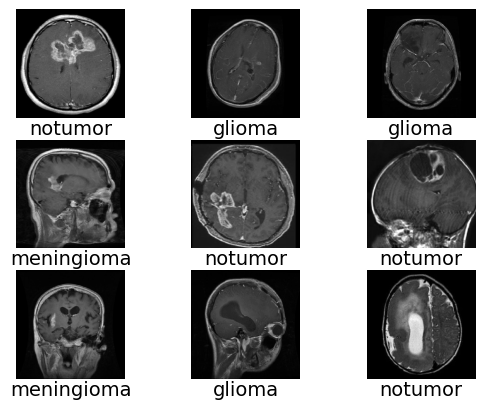

In [16]:
predictions_test = model.predict(X_testing)
predicted_labels_test = np.argmax(predictions_test, axis=1)

for i in range(9): 
    plt.subplot(3, 3, i+1)
    plt.imshow(X_testing[i], cmap='gray')
    plt.axis('off')
    plt.text(0.5, -0.15, classes_test[predicted_labels_test[i]], fontsize=14, ha='center', transform=plt.gca().transAxes)

In [17]:
from sklearn.metrics import classification_report, accuracy_score

y_pred_prob = model.predict(X_testing)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_testing, axis=1)

accuracy = accuracy_score(y_true, y_pred)

print("Accuracy: ", accuracy)
print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes
    )
)

50/50 [==============================] - 21s 425ms/step
Accuracy:  0.764375
              precision    recall  f1-score   support

      glioma       0.90      0.57      0.70       400
  meningioma       0.69      0.55      0.61       400
     notumor       0.65      1.00      0.79       400
   pituitary       0.90      0.94      0.92       400

    accuracy                           0.76      1600
   macro avg       0.79      0.76      0.75      1600
weighted avg       0.79      0.76      0.75      1600



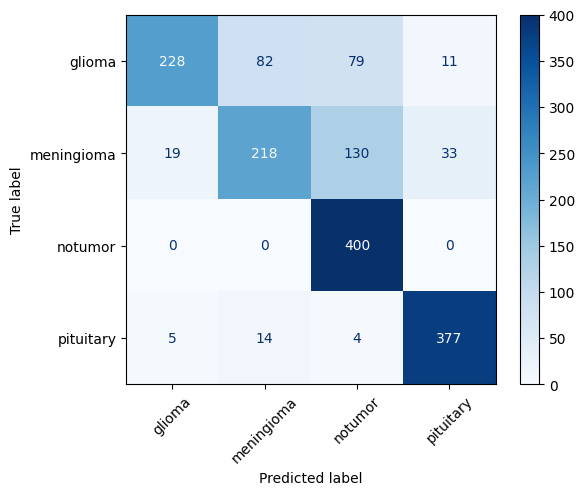

[[228  82  79  11]
 [ 19 218 130  33]
 [  0   0 400   0]
 [  5  14   4 377]]


In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=classes
)

disp.plot(cmap='Blues', xticks_rotation=45)
plt.show()

print(cm)

In [19]:
y_pred_prob = model.predict(X_val)

notumor_idx = classes.index('notumor')
tumor_indices = [
    i for i, name in enumerate(classes)
    if name != 'notumor'
]

threshold = 0.5

y_pred = []

for prob in y_pred_prob: 
    tumor_prob = np.sum(prob[tumor_indices])

    if tumor_prob >= threshold: 
        tumor_class = tumor_indices[
            np.argmax(prob[tumor_indices])
        ]

        y_pred.append(tumor_class)
    else: 
        y_pred.append(notumor_idx)

y_pred = np.array(y_pred)
y_true = np.argmax(y_val, axis=1)

print(
    classification_report(
        y_true, 
        y_pred,
        labels=list(range(len(classes))),
        target_names=classes,
        digits=4,
        zero_division=0
    )
)

35/35 [==============================] - 16s 461ms/step
              precision    recall  f1-score   support

      glioma     0.9313    0.7750    0.8460       280
  meningioma     0.7836    0.7500    0.7664       280
     notumor     0.8850    0.9893    0.9342       280
   pituitary     0.8725    0.9536    0.9113       280

    accuracy                         0.8670      1120
   macro avg     0.8681    0.8670    0.8645      1120
weighted avg     0.8681    0.8670    0.8645      1120



In [21]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.10.0
GPU: []
